# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import RegularGridInterpolator
import astropy.constants as c
from astropy.cosmology import FlatLambdaCDM

NETID = 'asteves2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

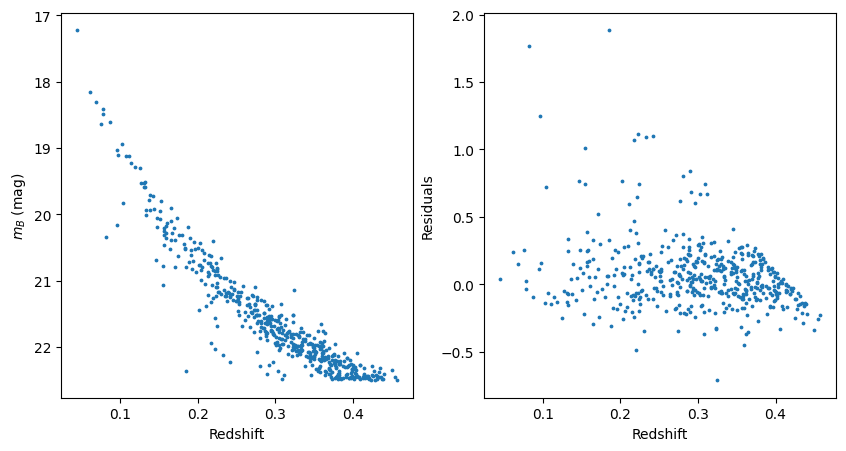

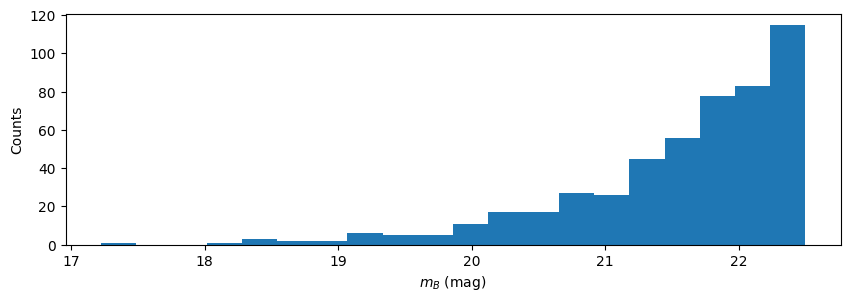

Calculated     FlatLamba    Difference
  36.4841        36.4843     2.279e-04
  37.2101        37.2101     3.923e-05
  37.4502        37.4503     1.202e-04
  37.6726        37.6727     9.377e-05
  37.7480        37.7480     2.654e-06
  37.7570        37.7571     6.687e-05
  37.8710        37.8710     4.024e-05
  37.9979        37.9979     2.992e-06
  38.2124        38.2124     6.234e-05
  38.2211        38.2211     2.798e-05


In [143]:
# Part 1: your work here
H0 = 70

z_grid = np.linspace(0, 0.75, 500)
o_grid = np.arange(0.05, 0.7 + 1e-9, 0.005)

integrand = 1 / np.sqrt(o_grid[:, None] * (1 + z_grid[None, :])**3 + 1 - o_grid[:, None])

dl = (1 + z_grid) * c.c.value / 1000 / H0 * cumulative_trapezoid(integrand, z_grid, axis = 1, initial = 0)
mu_tab = 5 * np.log10(dl[:, 1:]) + 25

m_interp = RegularGridInterpolator((o_grid, z_grid[1:, ]), mu_tab)

FlabLam = FlatLambdaCDM(H0 = 70, Om0 = 0.3).distmod(z)

def mu(z, Om):
    z = np.asarray(z)
    return m_interp(np.column_stack([np.full(z.size, Om), z.ravel()])).reshape(z.shape)

resid = (m + 19.30) - mu(z, 0.3)

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 5))

ax[0].scatter(z, m, s = 3)
ax[0].set_xlabel('Redshift')
ax[0].set_ylabel(r'$m_B$ (mag)')
ax[0].yaxis.set_inverted(True)


ax[1].scatter(z, resid, s = 3)
ax[1].set_xlabel('Redshift')
ax[1].set_ylabel(r'Residuals')

bins=np.arange(m.min(), m.max() + 0.1, 0.1)

bins = 20
fig = plt.figure(figsize = (10, 3))
plt.hist(m, bins = bins)

plt.xlabel(r'$m_B$ (mag)')
plt.ylabel('Counts')

plt.show()

print('Calculated     FlatLamba    Difference')
_mu = mu(z, 0.3)
for i in range(10):
    print(f'  {_mu[i]:.4f}        {FlabLam[i].value:.4f}     {np.abs(_mu[i] - FlabLam[i].value):.3e}')

I was unable to embed the PNG directly into the notebook, so I'll include it in the pull request for this lab.

In [144]:
M_lim = 22.5

def simulate(f, Omega, rng, n_keep = 500, batch = 3000):

    z_out, m_out, t_out = [], [], []

    n_have = 0
    while n_have < n_keep:
        a, b = 0.01, 0.7
        u = rng.random(batch)
        z_s = (a**3 + u * (b**3 - a**3))**(1/3)

        T = rng.random(batch) < f
        M = np.where(T, rng.normal(-18.5, 0.5, batch), rng.normal(-19.3, 0.12, batch))
        m_s = M + mu(z_s, Omega) + rng.normal(0, 0.1, batch)

        I = m_s <= M_lim
        z_out.append(z_s[I])
        m_out.append(m_s[I])
        t_out.append(T[I])

        n_have += I.sum()

    z_s = np.concatenate(z_out)[: n_keep]
    m_s = np.concatenate(m_out)[: n_keep]
    T_s = np.concatenate(t_out)[: n_keep]

    return z_s, m_s ,T_s

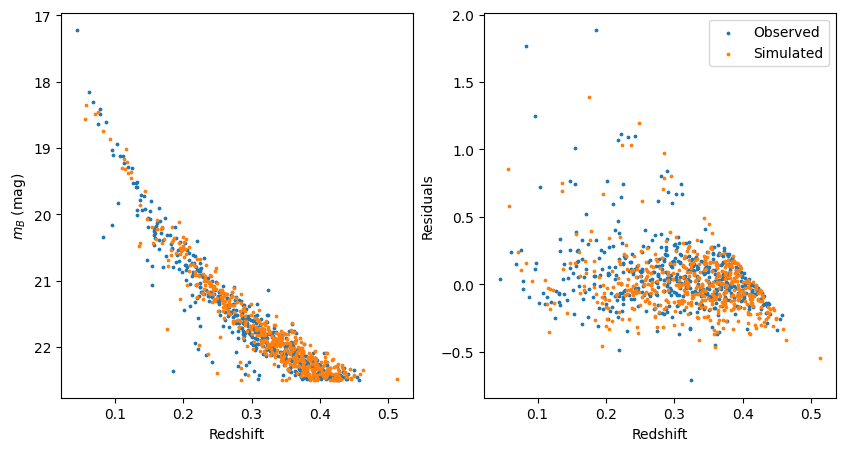

In [145]:
z_sim, m_sim, T_sim = simulate(0.1, 0.3, rng = np.random.default_rng(42))

resid_sim = (m_sim + 19.30) - mu(z_sim, 0.3)

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 5))
ax[0].scatter(z, m, s = 3, label = 'Observed')
ax[0].scatter(z_sim, m_sim, s = 3, label = 'Simulated')
ax[0].set_xlabel('Redshift')
ax[0].set_ylabel(r'$m_B$ (mag)')
ax[0].yaxis.set_inverted(True)


ax[1].scatter(z, resid, s = 3, label = 'Observed')
ax[1].scatter(z_sim, resid_sim, s = 3, label = 'Simulated')
ax[1].set_xlabel('Redshift')
ax[1].set_ylabel(r'Residuals')
ax[1].legend()

plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

From the part 1 plots, the type Ia supernovae follow a well-defined trend, from lower magnitudes at lower redshifts to higher magnitudes at higher redshifts. The residuals seem to generally sit around zero, so most supernovae follow the trand as defined by the $m_{b}$ vs $z$ plot. I found a very small difference between the interpolated and astropy distance moduli, as they agree to within about $10^{-4}$ magnitudes. The description doesn't provide a magnitude upper limit, so the dimmest supernovae are binned around 22 instead of tailing off to some dimmer value. This means that there is a Malmquist bias that exists from the fact that there is a technologically or methodologically induced barrier for the dimmest supernovae that would have otherwise been studied. To deal with this issue, I only kept simulated supernovae with a magnitude less that the upper limit defined by the histogram (~22.5). To replicate the dataset, the core-collapse fraction is used to model the absolute magnitude $M$ by way of the latent variable $T_{i}$, a Bernoulli distribution deciding whether a supernova is an impostor or not. The absolute magnitudes of each supernova are randomly sampled from a Gaussian distribution. The apparent magnitude can then be calculated with the distance modulus and some random error also drawn from a Gaussian. I simulated 500 new supernovae at $\Omega = 0.3$ because it was previously given, so I keep it here as a guess, and $f = 0.1$ because at this probability, only 10% of all drawn supernovae will be impostors. These values produce datasets that generally follow the same trends as the observed data, but with seemingly higher variance. In experimenting with difference values of $f$ it seems that the simulated data points approch the observed data as $f$ approaches 1, which could imply a very high impostor rate or errors in the simulation.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

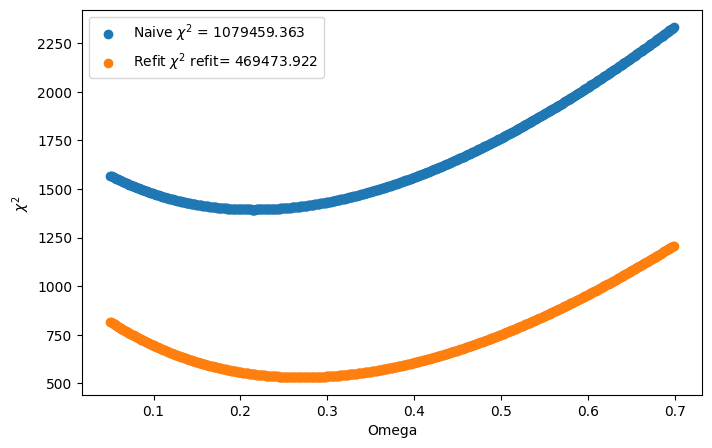

Upper error: 0.013              Refit upper error: 0.001
Lower error: 0.013              Refit lower error: 0.109
Omega_m: 0.215 +/- 0.013        Refit omega_m: 0.270 +/- 0.109


In [146]:
# Part 2: your work here

Om_range = np.arange(0.05, 0.7, 0.001)
sig_tot = 0.12**2 + 0.10**2

chi2 = np.array([np.sum((m + 19.3 - mu(z, Om))**2 / sig_tot) for Om in Om_range])
k = np.argmin(chi2)

inside = Om_range[chi2 <= chi2[k] + 1]
Om_hat, lo, hi = Om_range[k], inside.min(), inside.max()

mask = resid > 0.5
z_masked, m_masked = z[~mask], m[~mask]
chi2_refit = np.array([np.sum((m_masked + 19.3 - mu(z_masked, Om))**2 / sig_tot) for Om in Om_range])

k_refit = np.argmin(chi2_refit)

inside_refit = Om_range[chi2 <= chi2[k_refit] + 1]
Om_hat_refit, lo_refit, hi_refit = Om_range[k_refit], inside_refit.min(), inside_refit.max()

fig = plt.figure(figsize = (8, 5))
plt.scatter(Om_range, chi2, label = f'Naive $\chi^2$ = {np.sum(chi2):.3f}')
plt.scatter(Om_range, chi2_refit, label = f'Refit $\chi^2$ refit= {np.sum(chi2_refit):.3f}')
plt.xlabel(f'Omega')
plt.ylabel(f'$\chi^2$ ')

plt.legend()
plt.show()

print(f'Upper error: {hi - Om_hat:.3f}              Refit upper error: {hi_refit - Om_hat_refit:.3f}')
print(f'Lower error: {Om_hat - lo:.3f}              Refit lower error: {Om_hat_refit - lo_refit:.3f}')
print(f'Omega_m: {Om_hat:.3f} +/- {Om_hat - lo:.3f}        Refit omega_m: {Om_hat_refit:.3f} +/- {Om_hat_refit - lo_refit:.3f}')

**ANSWER (the naive fit, then why the impostors push it the way they do):**

I calculated $\Omega_m = 0.215 \pm 0.013$. In the Hubble diagram from part 1 it seems that imposters tend to be at higher magnitudes at the same redshifts then real type Ia supernovae. Impostor supernovae then must have a larger distance modulus, where because the redshifts are fixed, the values of $\Omega$ must be pulled down. After removing all supernovae with residuals > 0.5 mag, the value for $\Omega_m$ jumps up to $0.270 \pm 0.109$ which is about 4 standard deviations from the initial $\Omega$ value. The quoted value for the refit $\Omega_m$ however is not the true value because the residual cut I employed is a rough one, and there still exists the upper limit on magnitude so that only brighter supernovae are sampled.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

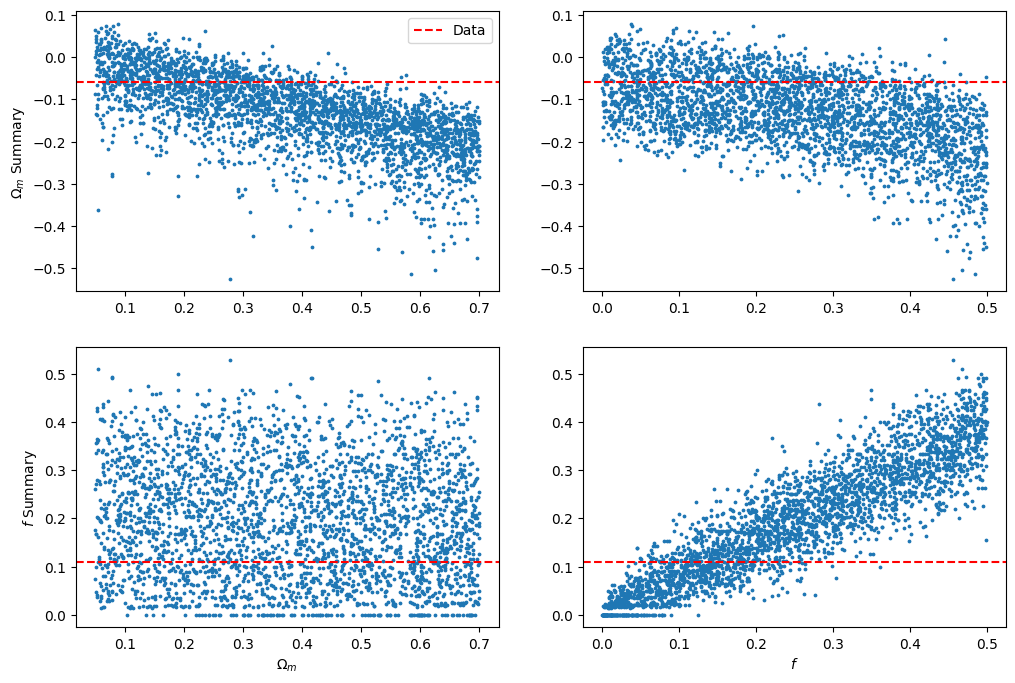

In [147]:
# Part 3: your work here

n = 50000
rng = np.random.default_rng(457)
Om_draw = rng.uniform(0.05, 0.7, n)
f_draw = rng.uniform(0.0, 0.5, n)

def summary(z, m):
    r = m + 19.3 - mu(z, 0.3)
    hi, low = z > 0.3, z < 0.2

    omega_sum = np.median(r[hi]) - np.median(r[low])
    f_sum = np.mean(r[low] > 0.4)

    return omega_sum, f_sum

S = np.array([summary(*simulate(f_draw[j], Om_draw[j], rng)[: 2]) for j in range(n)])
S_obs = np.array(summary(z, m))

df = pd.DataFrame({'Omega Summary': S[:, 0], 'f Summary': S[:, 1],
                   'Omega Observed': S_obs[0], 'f Observed': S_obs[1]})
df.to_csv('/Users/andrewsteves/ast457_2026_Fall/submissions/asteves2/Lab09_summaries.csv', index = False)

fig, ax = plt.subplots(nrows = 2, ncols = 2, figsize = (12, 8))

ax[0, 0].scatter(Om_draw[: 3000], S[: 3000 , 0], s = 3)
ax[0, 1].scatter(f_draw[: 3000], S[: 3000, 0], s = 3)

ax[0, 0].set_ylabel(r'$\Omega_m$ Summary')

ax[1, 0].scatter(Om_draw[: 3000], S[: 3000, 1], s = 3)
ax[1, 1].scatter(f_draw[: 3000], S[: 3000, 1], s = 3)

ax[1, 0].set_xlabel(r'$\Omega_m$'); ax[1, 1].set_xlabel(r'$f$')
ax[1, 0].set_ylabel(r'$f$ Summary')

for j in range(2):
    ax[0, j].axhline(S_obs[0], linestyle = '--', color = 'red', label = 'Data')
    ax[1, j].axhline(S_obs[1], linestyle = '--', color = 'red')

ax[0, 0].legend()
plt.show()

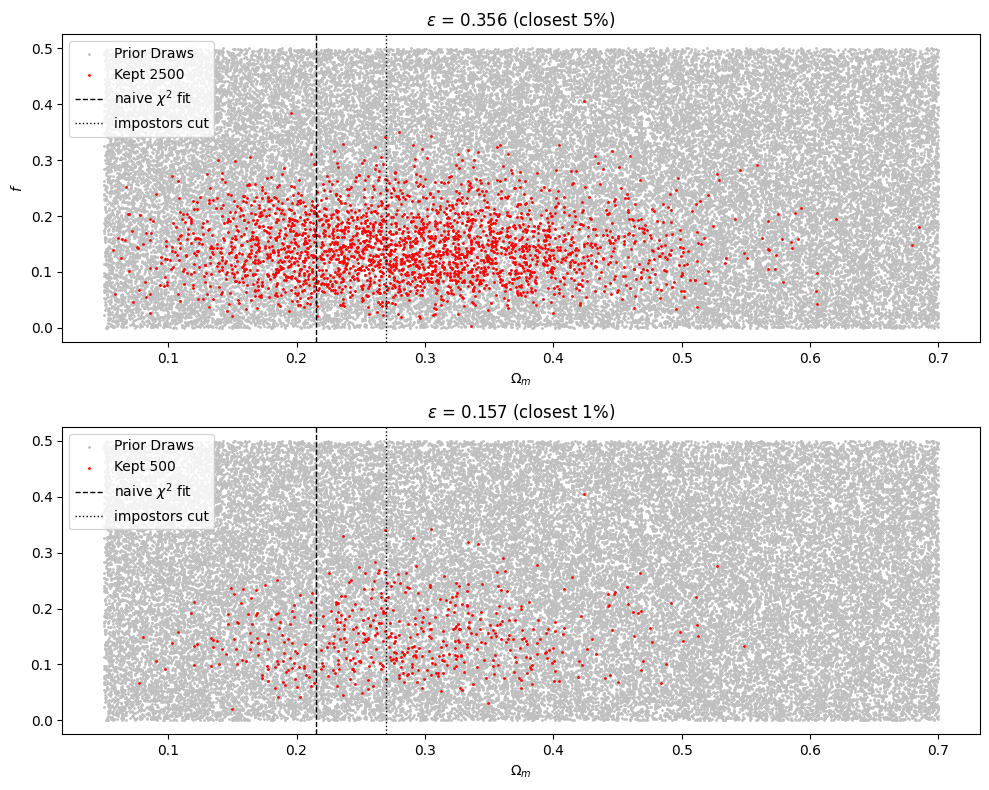

In [148]:
summaries = pd.read_csv('Lab09_summaries.csv')

Om, f, Om_obs, f_obs = summaries['Omega Summary'], summaries['f Summary'], summaries['Omega Observed'], summaries['f Observed']

scale_Om, scale_f = np.std(Om), np.std(f)
D = np.sqrt(((Om - Om_obs) / scale_Om)**2 + ((f - f_obs) / scale_f)**2)

fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (10, 8))

for a, q in zip(ax, [0.05, 0.01]):
    eps = np.quantile(D, q)
    keep = D <= eps

    a.scatter(Om_draw, f_draw, s = 1, c = '0.75', label = 'Prior Draws')
    a.scatter(Om_draw[keep], f_draw[keep], s = 1, color = 'r', label = f'Kept {np.sum(keep)}')
    a.axvline(0.215, color='k', ls='--', lw=1, label=r'naive $\chi^2$ fit')
    a.axvline(0.270, color='k', ls=':',  lw=1, label='impostors cut')

    a.set_title(f'$\\epsilon$ = {eps:.3f} (closest {q:.0%})')
    a.set_xlabel(r'$\Omega_m$')

ax[0].set_ylabel('$f$')
ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.show()

In [149]:
for q in [0.1, 0.05, 0.02, 0.01, 0.005]:
    keep = D <= np.quantile(D, q)
    Om_keep, f_keep = Om_draw[keep], f_draw[keep]
    p_O = np.percentile(Om_keep, [2.5, 16, 50, 84, 97.5])
    p_f = np.percentile(f_keep, [2.5, 16, 50, 84, 97.5])

    print(f'q={q} (n = {keep.sum()}): Omega = {p_O[2]:.3f} 68%: [{p_O[2] - p_O[1]:.3f}, {p_O[3]-p_O[2]:.3f}], 95%: [{p_O[0]:.3f}, {p_O[4]:.3f}], '
          f'f = {p_f[2]:.3f} 68%: [{p_f[2] - p_f[1]:.3f}, {p_f[3]-p_f[2]:.3f}], 95%: [{p_f[0]:.3f}, {p_f[4]:.3f}]')

q=0.1 (n = 5000): Omega = 0.288 68%: [0.110, 0.122], 95%: [0.095, 0.532], f = 0.142 68%: [0.060, 0.069], 95%: [0.042, 0.282]
q=0.05 (n = 2500): Omega = 0.285 68%: [0.099, 0.104], 95%: [0.112, 0.496], f = 0.141 68%: [0.055, 0.064], 95%: [0.046, 0.274]
q=0.02 (n = 1000): Omega = 0.282 68%: [0.087, 0.098], 95%: [0.126, 0.479], f = 0.144 68%: [0.053, 0.062], 95%: [0.058, 0.266]
q=0.01 (n = 500): Omega = 0.282 68%: [0.084, 0.092], 95%: [0.134, 0.469], f = 0.145 68%: [0.052, 0.066], 95%: [0.059, 0.272]
q=0.005 (n = 250): Omega = 0.285 68%: [0.086, 0.095], 95%: [0.134, 0.469], f = 0.147 68%: [0.050, 0.075], 95%: [0.066, 0.288]


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

The summary for $\Omega_m$ will be the difference in median residual at high redshift and low redshift, because part 1 showed that $\mu$ is not very dependent on $\Omega_m$ at low $z$ and has significant dependence on $\Omega_m$ at high $z$. Here I will $z < 0.2$ for low redshifts and $z > 0.3$ for high redshifts. The summary of $f$ will be the fraction of residuals above 0.4 mag at low $z$ because this is where more impostor galaxies will sit as opposed to low residuals at mid to high redshifts. The $\Omega_m$ summary vs $\Omega_m$ shows a clear downward trend, resulting in an offset of roughly 0.25 mag over the range of its priors. This implies that matter makes more distant supernovae brighter than the 0.3 reference, so the high z median residual falls. Similarly, the $f$ summary vs $f$ has a strong linear trend implying that simulations with more impostors have faint outliers. The $\Omega_m$ summary vs $f$ also shows a clear downward trend, however it is not flat likely due to the fact that impostors survive mostly at low redshift. The low redshift impostors mean that the low mean residual median increases and high residual mean decreases meaning that $\Omega_m$ is not entirely independent of $f$. The $f$ summary vs $\Omega_m$ shows a nearly linear trend, due to the dependence between the two parameters.

After running over many possible values for epsilon, there was very little variation in the medians of $\Omega_m$ and $f$, so the posterior likely doesn't depend heavily on $\epsilon$. In $\Omega_m$ the 68% and 95% intervals narrow from 0.10 to 0.01 then stagnate, however the intervals on $f$ do start to widen between 0.01 and 0.005 which is likely due to the very small number of kept supernovae when compared to the total. Here I'll choose $\epsilon = 0.01$ because for both parameters because both intervals have stopped narrowing and begin to widen again at smaller values. The vertical lines on the plots represent the median $\Omega_m$ values from part 2. We can see that the naive fit (no cuts made) sits well below the actual median value of $\Omega_m$ by about 0.07 or 5 times its own error bar. After cutting a portion of impostors, the median value of $\Omega_m$ is much closer to the actual median value being within one standard deviation. At $\epsilon = 0.01$, the percentage of impostor supernovae is $f = 0.145$, so I expect there to be around 72 impostors in the dataset. We can see that from the intervals, the kept draws fall smoothly on both sides with all intervals falling well within the defined prior ranges, so the data is setting the median and not the prior itself.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

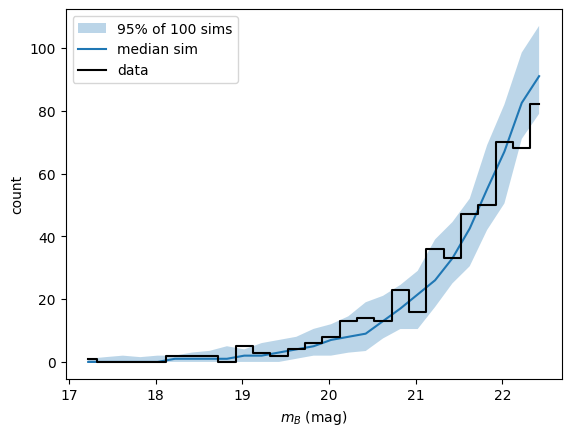

In [153]:
# Part 4: your work here

rng = np.random.default_rng(457)
idx = rng.choice(np.flatnonzero(keep), 100, replace = False)
sims = [simulate(Om_draw[j], f_draw[j], rng) for j in idx]

bins = np.arange(m.min() - 0.1, m.max() + 0.1, 0.2)
H = np.array([np.histogram(s[1], bins)[0] for s in sims])
mid = (bins[1:] + bins[:-1]) / 2

plt.fill_between(mid, *np.percentile(H, [2.5, 97.5], axis=0), alpha=0.3, label='95% of 100 sims')
plt.plot(mid, np.median(H, 0), 'C0', label='median sim')
plt.step(mid, np.histogram(m, bins)[0], 'k', where='mid', label='data')
plt.xlabel('$m_B$ (mag)')
plt.ylabel('count')
plt.legend()
plt.show()

In [151]:
scale_Om, scale_f = np.std(Om), np.std(f)
rng = np.random.default_rng(457)
tests = rng.choice(len(Om), 200, replace = False)

hit_O, hit_f = [], []
for t in tests:
    d = np.sqrt(((Om - Om[t]) / scale_Om)**2 + ((f - f[t]) / scale_f)**2)

    k = d <= np.quantile(d, 0.01)
    lo_O, hi_O = np.percentile(Om_draw[k], [2.5, 97.5])
    lo_f, hi_f = np.percentile(f_draw[k], [2.5, 97.5])
    hit_O.append(lo_O <= Om_draw[t] <= hi_O)
    hit_f.append(lo_f <= f_draw[t] <= hi_f)

print(f'Omega_m coverage: {np.mean(hit_O):.2f},  f coverage: {np.mean(hit_f):.2f}')


Omega_m coverage: 0.94,  f coverage: 0.96


**ANSWER (the check, the coverage, and the assumption):**

For 100 ABC draws from the posterior ($\epsilon = 1$), I simulated a survey and histogrammed its apparent magnitudes in 0.2 mag bins. From the graph, we can see that most of the most of the simulated data do fall within the 95% interval. However, at around 21.1 mag the simulated data does drop below the lower 5% bound which may be insignificant but could also mean that the simulator can't accurately predict counts at this magnitude. The observed counts lie inside the 95% of 100 posterior samples in all but one bin. The simulator does seem to have honest intervals for both $\Omega_m$ and $f$ with coverages of 0.94 and 0.96 respectively. This simulator assumes equal performance at all redshifts, so that f is constant. This assumption breaks down in a real survey because at higher redshifts supernovae become fainter and fewer good detections are possible, so more impostors appear in this range. The redshift of the impostors is higher at the same redshift, so the only way o make high redshift supernovae fainter at is a larger distance modulus, which means lowering $\Omega_m$.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

In this lab AI was used to summarize information from the lectures and textbook as well as general debugging. Additionally, the histogram in part 4 was generated by claude code.

**REFLECTION:**
One place that AI analysis could have gone wrong is in the correlation of $\Omega_m$ and $f$. In the $\Omega_m$ summary vs $f$ plot, an AI agent may not have picked up on the slight curvature at high $f$ missing out on the fact that there is some correlation between $\Omega_m$ and $f$.


**VERIFICATION PLAN:**

In part 2, after fitting the naive $\chi^2$ I cut all supernovae with residuals greater than 0.5 because these supernovae are faint at a high redshift which is where we expect impostors. After refitting with the cut data, I found that the new $\Omega_m$ was 4 naive fit standard deviations away from the naive value, at a significantly lower $\chi^2$. I then used this result in part 3 to determine if the ABC values for $\Omega_m$ at varying $\epsilon$ were accurate or not. After selecting the values for $\Omega_m$ and $f$ at $\epsilon = 0.01$, the refit data was within one standard deviation of the ABC value.